# Clustering Track
Fits K-Means and Agglomerative Hierarchical clustering without using `CASE_OUTCOME` or `RESOLUTION_DAYS`
during `.fit()`.

**Requires `preprocessing.ipynb` to have been run first** (produces `data/processed/model_ready_data.pkl`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import joblib

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

### Load preprocessed data

In [2]:
artifacts = joblib.load("../data/processed/model_ready_data.pkl")
X_train_final = artifacts["X_train_final"]
RANDOM_STATE = artifacts["RANDOM_STATE"]

CLUSTER_SAMPLE_SIZE = 15000
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_train_final.index, size=CLUSTER_SAMPLE_SIZE, replace=False)
X_cluster = X_train_final.loc[sample_idx]

print("Clustering feature matrix:", X_cluster.shape)

Clustering feature matrix: (15000, 37)


#### 1. K-Means Clustering

Elbow curve — K-Means

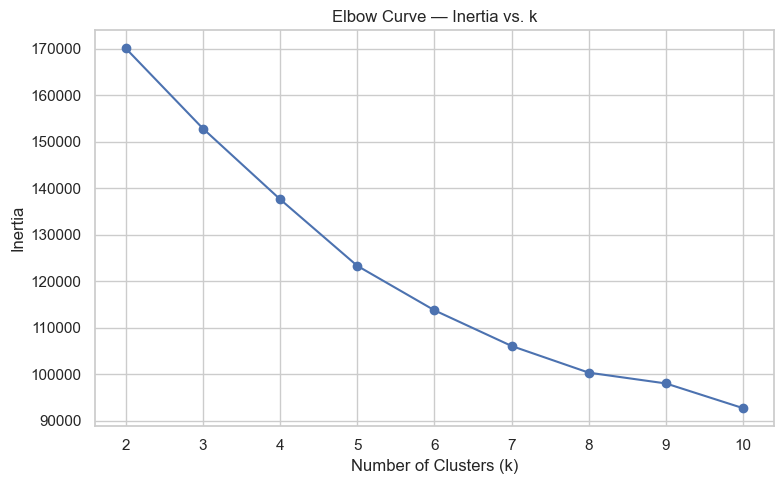

In [3]:
k_range = range(2, 11)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_range), inertias, marker="o", color="#4C72B0")
ax.set_title("Elbow Curve — Inertia vs. k")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Inertia")
ax.set_xticks(list(k_range))
plt.tight_layout()
plt.show()

In [4]:
K_CHOSEN = 5

kmeans_final = KMeans(n_clusters=K_CHOSEN, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_cluster)

print(f"K-Means fit with k={K_CHOSEN}.")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means fit with k=5.
0    5089
1    3844
2    5070
3     446
4     551
Name: count, dtype: int64


#### 2. Agglomerative Hierarchical Clustering

Dendrogram — Ward, Complete, and Average linkage

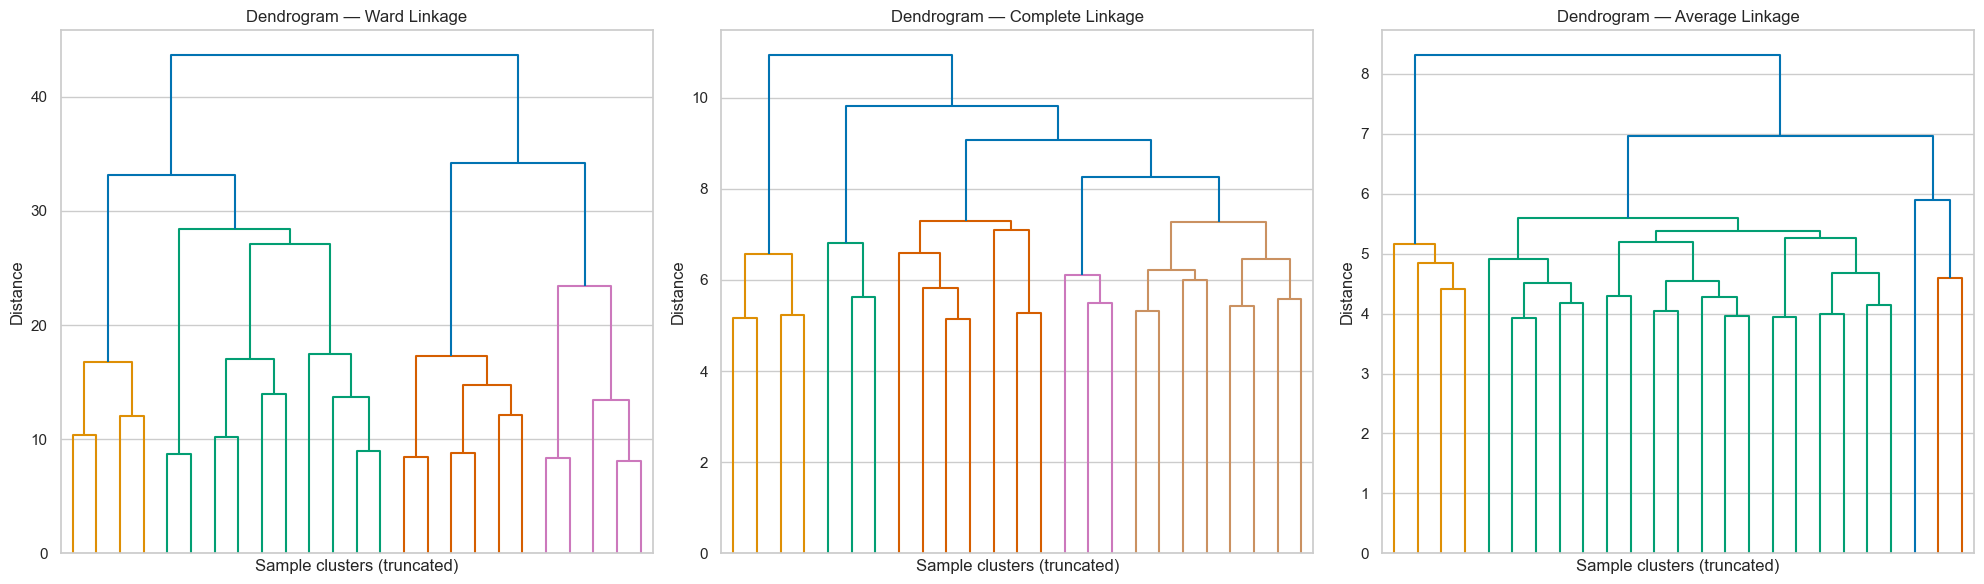

In [5]:
DENDRO_SAMPLE_SIZE = 500
dendro_idx = rng.choice(len(X_cluster), size=DENDRO_SAMPLE_SIZE, replace=False)
X_dendro = X_cluster.iloc[dendro_idx]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, method in zip(axes, ["ward", "complete", "average"]):
    Z = linkage(X_dendro, method=method)
    dendrogram(Z, ax=ax, truncate_mode="lastp", p=25, no_labels=True)
    ax.set_title(f"Dendrogram — {method.capitalize()} Linkage")
    ax.set_xlabel("Sample clusters (truncated)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

In [6]:
LINKAGE_CHOSEN = "ward"

agglo_final = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=LINKAGE_CHOSEN)
agglo_labels = agglo_final.fit_predict(X_cluster)

print(f"Agglomerative Clustering fit with linkage='{LINKAGE_CHOSEN}', n_clusters={K_CHOSEN}.")
print(pd.Series(agglo_labels).value_counts().sort_index())

Agglomerative Clustering fit with linkage='ward', n_clusters=5.
0    1412
1    7575
2    3474
3     566
4    1973
Name: count, dtype: int64


### Evaluation metrics

In [7]:
cluster_metrics = []
for name, labels in [("K-Means", kmeans_labels), ("Agglomerative Hierarchical", agglo_labels)]:
    cluster_metrics.append({
        "Algorithm": name,
        "Silhouette": silhouette_score(X_cluster, labels),
        "Davies-Bouldin": davies_bouldin_score(X_cluster, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_cluster, labels),
    })

cluster_metrics_df = pd.DataFrame(cluster_metrics)
cluster_metrics_df

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.184863,1.563674,2511.508967
1,Agglomerative Hierarchical,0.209805,1.587768,2356.562759


### Cluster visualisation

PCA 2D scatter — K-Means and Agglomerative

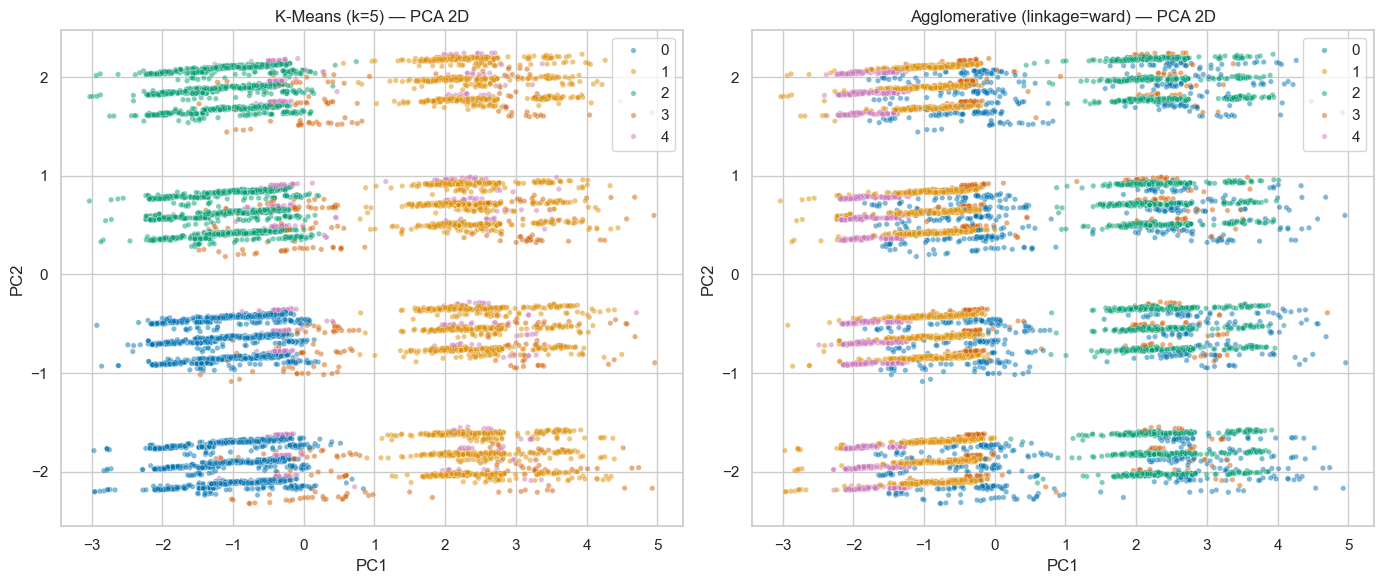

In [8]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_cluster_2d = pca_2d.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(x=X_cluster_2d[:, 0], y=X_cluster_2d[:, 1], hue=kmeans_labels,
                 palette="colorblind", alpha=0.5, s=15, ax=axes[0], legend="full")
axes[0].set_title(f"K-Means (k={K_CHOSEN}) — PCA 2D")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sns.scatterplot(x=X_cluster_2d[:, 0], y=X_cluster_2d[:, 1], hue=agglo_labels,
                 palette="colorblind", alpha=0.5, s=15, ax=axes[1], legend="full")
axes[1].set_title(f"Agglomerative (linkage={LINKAGE_CHOSEN}) — PCA 2D")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

t-SNE 2D scatter — K-Means

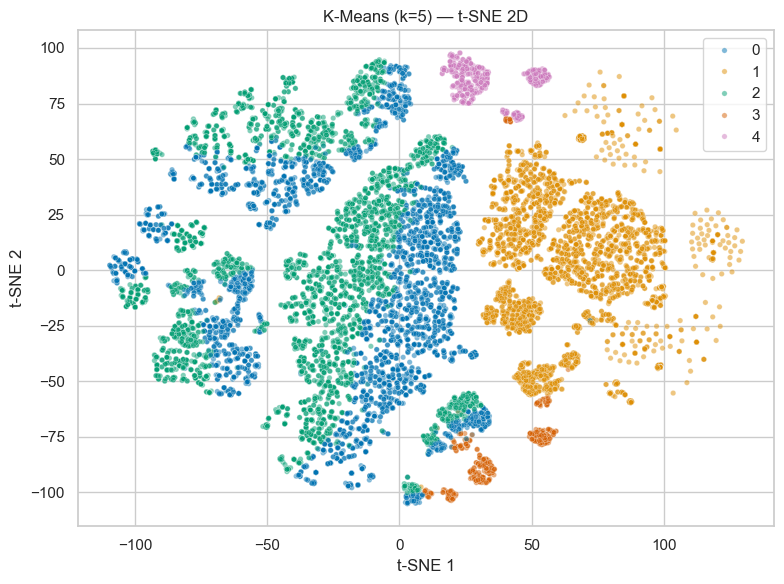

In [9]:
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init="pca")
X_cluster_tsne = tsne.fit_transform(X_cluster)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_cluster_tsne[:, 0], y=X_cluster_tsne[:, 1], hue=kmeans_labels,
                 palette="colorblind", alpha=0.5, s=15, ax=ax, legend="full")
ax.set_title(f"K-Means (k={K_CHOSEN}) — t-SNE 2D")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

### Save results

In [10]:
import os
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

joblib.dump({
    "cluster_metrics_df": cluster_metrics_df,
    "K_CHOSEN": K_CHOSEN,
    "LINKAGE_CHOSEN": LINKAGE_CHOSEN,
}, "../data/processed/clustering_results.pkl")

joblib.dump(kmeans_final, "../models/kmeans_model.pkl")

print("Saved clustering results and K-Means model.")

Saved clustering results and K-Means model.
